# Multimodal Music Analysis

The target of this project is the implementation of a complete pipeline for extracting knowledge from music data by combining two different modalities: **Audio** and **Text**. The project is split into two parts:  
1. Preprocessing of the data, generation of embeddings and researching analysis.
2. Classification, Fusion and Evaluation.  
  
This notebook contains the implementation of part 1.


Requirements:

In [ ]:
%pip install seaborn
%pip install datasets
%pip install matplotlib
%pip install vaderSentiment
%pip install kneed
%pip install contractions
%pip install pyspellchecker
%pip install scikit-learn
%pip install pandas
%pip install wordcloud
%pip install tensorflow
%pip install gensim

## 1. Data Collection


In [110]:
import pandas as pd
import os

import numpy as np
import tensorflow as tf
import sklearn

import matplotlib.pyplot as plt

- Run the code in the next sections for pre-processing the data 
- In case the file already exists, the next sections are skipped automatically

In [132]:
def keep_top_n(df, column, n):
    top_values = df[column].value_counts().head(n+1).index.to_list()[1:n+1]
    # print(f"Top {n} values in column '{column}': {top_values}")
    filtered_df = df[df[column].isin(top_values)]
    return filtered_df

In [133]:
def create_lyrics_df(target_ids, path='data/processed_lyrics'):
    # --- Filtering the lyrics of the songs ---
    lyrics_folder = path

    lyrics_data = []

    for filename in os.listdir(lyrics_folder):
        if filename.endswith('.txt'):
            song_id = filename.replace('.txt', '')
            
            if song_id in target_ids:
                file_path = os.path.join(lyrics_folder, filename)
                
                with open(file_path, 'r', encoding='utf-8') as f:
                    lyrics_text = f.read()
                
                lyrics_data.append({
                    'id': song_id,
                    'lyrics': lyrics_text
                })

    lyrics_df = pd.DataFrame(lyrics_data)
    return lyrics_df

In [134]:
def merge_dataframes(dfs, merge_on):
    merged_df = dfs[0]

    for df in dfs[1:]:
        merged_df = pd.merge(merged_df, df, on=merge_on)

    return merged_df


In [135]:

def collect_data():
    # --- Importing the datasets ---
    genres_df = pd.read_csv('data/id_genres.csv', sep='\t') 
    information_df = pd.read_csv('data/id_information.csv', sep='\t')
    tags_df = pd.read_csv('data/id_tags.csv', sep='\t')
    mfcc_stats_df = pd.read_csv('data/id_mfcc_stats.tsv', sep='\t').dropna()

    # ---- Group mfcc stats in one column for better data ----
    mfcc_stats_df = mfcc_stats_df.copy()

    mfcc_columns = [col for col in mfcc_stats_df.columns if 'mfcc' in col.lower() or 'cov' in col.lower()]

    mfcc_stats_df['audio_stats'] = mfcc_stats_df[mfcc_columns].values.tolist()

    audio_stats_df = mfcc_stats_df.drop(columns=mfcc_columns)

    # --- Filtering the genres dataset to only include the top n most common genres ---
    filtered_genres_df = keep_top_n(genres_df, "genres", 5)

    # --- Create dataframe with the lyrics of the songs ---
    lyrics_df = create_lyrics_df(target_ids=set(filtered_genres_df['id'].astype(str)))

    # --- Merging dataframes ---
    dataframes = [filtered_genres_df, information_df, tags_df, audio_stats_df, lyrics_df]
    df = merge_dataframes(dataframes, "id")

    # --- Handling missing and duplicate values ---
    df = df[df['lyrics'].notna()]
    df = df[df['lyrics'].str.strip() != '']
    df = df[df['genres'].notna()]
    df = df[df['genres'].str.strip() != '']
    df = df.drop_duplicates(subset='id', keep='first')

    return df
    

In [137]:
final_df_path = "data/final_data.pkl"
if (os.path.isfile(path=final_df_path)):
    data = pd.read_pickle(final_df_path,)
else:
    data = collect_data()
    data = data.drop(columns=["artist", "album_name"])
    data.to_pickle(final_df_path)
    
data.head()

,id,genres,song,tags,audio_stats,lyrics
0,00P2bHdWFkghmDqz,soul,Tell Me a Tale,"fip,soul","[23.64550018310547, -2.017793893814087, -7.855...",tell tale alway sing song alway tell stori rea...
2,01EKNot8qVgZpKM7,rock,I For You,"rock,acoustic,just cant stand this song omg","[22.95288848876953, -3.5178918838500977, -9.76...",say word say say anoth day fragil word like cu...
3,01gyRHLquwXDlhkO,rap,Somebody's Gotta Die,"rap,hip-hop,gangsta rap,east coast rap","[22.731481552124023, -12.233457565307615, 2.38...",sittin crib dreamin leer jet coup way salt sho...
4,01zNMO11qGa7tLqa,rap,Duro Igual Concreto,"rap,brasil","[23.98007202148437, -13.340648651123049, 9.021...",come like readi accept propos without think en...
5,02H3FqI0CSBlYFo7,rock,Buried Alive by Love,"love metal,rock,finnish,gothic,him","[24.13726043701172, -13.588617324829102, -11.5...",burden lose rest upon shoulder weight seem unb...


## 2. Feature Extraction

### **Audio Embeddings**

### Autoencoder
Creating and training a simple Autoencoder to compress the vector of the audio embedding to a vector with fewer dimensions.

In [138]:
class Autoencoder(tf.keras.Model):
    def __init__(self, input_dim, encoding_dim=32):
        super(Autoencoder, self).__init__()

        layers = tf.keras.layers

        self.encoder = tf.keras.Sequential([
            layers.Input(shape=(input_dim,)),
            layers.Dense(64, activation='relu'),
            layers.BatchNormalization(),
            layers.Dropout(0.2),
            layers.Dense(encoding_dim, activation='relu')
        ])

        self.decoder = tf.keras.Sequential([
            layers.Input(shape=(encoding_dim,)),
            layers.Dense(64, activation='relu'),
            layers.BatchNormalization(),
            layers.Dropout(0.2),
            layers.Dense(input_dim, activation='linear')
        ])

    def call(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

In [139]:
from sklearn.preprocessing import StandardScaler
from keras.callbacks import EarlyStopping, TensorBoard


'''
Function to train the autoencoder.
Arguments:  - scaled audio_stats from the dataframe ready for training
            - optional: hyperparameters for the training
Returns:    - training history for visualization
            - the trained autoencoder
'''
def autoencoder_training(audio_stats, encoding_dim=32, optimizer="adam", loss="mse",
                         epochs=100, batch_size=32, early_stopping_epoch=20):

    input_dim = audio_stats.shape[1]

    # --- autoencoder ---
    autoencoder = Autoencoder(input_dim, encoding_dim)

    autoencoder.compile(optimizer=optimizer, loss=loss)

    # --- autoencoder training ---
    early_stopping = EarlyStopping(
        monitor='val_loss',
        patience=early_stopping_epoch,
        restore_best_weights=True
    )

    training = autoencoder.fit(audio_stats, audio_stats,
                        epochs=epochs,
                        batch_size=batch_size,
                        shuffle=True,
                        callbacks=[early_stopping],
                        validation_split=0.2)

    return training, autoencoder    


In [140]:
# --- Extraction the audio embeddings from the audio stats column ---
audio_embeddings = np.array(data["audio_stats"].to_list(), dtype=float)
scaler = StandardScaler()
audio_embed_train = scaler.fit_transform(audio_embeddings)

training, autoencoder = autoencoder_training(audio_stats=audio_embed_train)



Epoch 1/100
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.8181 - val_loss: 0.6402
Epoch 2/100
168/168 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.6206 - val_loss: 0.5280
Epoch 3/100
168/168 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.5302 - val_loss: 0.4727
Epoch 4/100
168/168 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4757 - val_loss: 0.4314
Epoch 5/100
168/168 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4394 - val_loss: 0.4106
Epoch 6/100
168/168 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4150 - val_loss: 0.3910
Epoch 7/100
168/168 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3954 - val_loss: 0.3776
Epoch 8/100
168/168 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3811 - val_loss: 0.3649
Epoch 9/100
168/168 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3672 - val_loss: 0.3566
Epoch 10/100
168/168 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3562 - val_loss: 0.3468
Epoch 11/100
168/168 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3466 - val_loss: 0.3375
Epoch 12/100
168/168 ━━━━━━━━━━━━━━━━━━━━

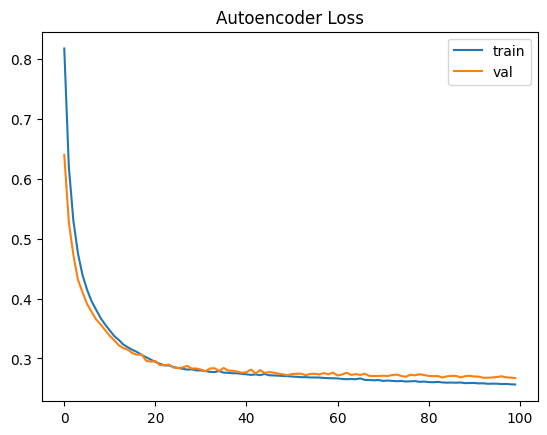

In [141]:
plt.plot(training.history['loss'], label='train')
plt.plot(training.history['val_loss'], label='val')
plt.legend()
plt.title("Autoencoder Loss")
plt.show()

In [142]:
# --- final compresses audio embeddings with 32 dim ---

autoenc_audio_embeddings = autoencoder.encoder.predict(audio_embed_train)
print(autoenc_audio_embeddings.shape)

210/210 ━━━━━━━━━━━━━━━━━━━━ 0s 620us/step
(6696, 32)


### Principal Component Analysis (PCA)

In [143]:
from sklearn.decomposition import PCA

audio_embeddings = np.array(data["audio_stats"].tolist(), dtype=float)
scaler = StandardScaler()
audio_scaled = scaler.fit_transform(audio_embeddings)


pca = PCA(n_components=0.95)  # keep 95% variance
pca_audio_embeddings = pca.fit_transform(audio_scaled)

pca_audio_embeddings.shape

(6696, 77)

In the next section, we compare the difference between PCA and Autoencoder audio embeddings, as well as the text embeddings to the audio embeddings.   

### **Text Embeddings**

In [144]:
import re
import numpy as np
from gensim.models import Word2Vec

#Προεπεξεργασία Lyrics

def preprocess_lyrics(text):
    if not isinstance(text, str):
        return []
    #Αφαίρεση περιεχομένου σε αγκύλες π.χ. [Chorus]
    text = re.sub(r'\[.*?\]', '', text)
    #Μετατροπή σε πεζά (για να αναγνωρίζουμε ίδιες λέξεις)
    text = text.lower()
    #Κρατάμε μόνο γράμματα και αποστροφές, όλα τα άλλα τα πετάμε πχ. αριθμούς
    text = re.sub(r"[^a-z\s']", '', text)
    #Βγάζουμε τα tokens τώρα αλλά όχι τις λέξεις με 2 ή λιγότερα γράμματα (είναι άχρηστες)
    tokens = [t for t in text.split() if len(t) >= 2]
    return tokens

#Εφαρμογή
print("Προεπεξεργασία lyrics...")
data['lyrics_tokens'] = data['lyrics'].apply(preprocess_lyrics)

#Παράδειγμα για να ελέγξουμε ότι το κάναμε σωστά
print(f"Παράδειγμα tokens:\n{data['lyrics_tokens'].iloc[32][:15]}")
print(f"Σύνολο τραγουδιών: {len(data)}")

Προεπεξεργασία lyrics...
Παράδειγμα tokens:
['conquer', 'fuck', 'respect', 'cocksuck', 'envi', 'cocksuck', 'anoth', 'fuck', 'mano', 'mina', 'bore', 'rhyme', 'fuck', 'enemi', 'friend']
Σύνολο τραγουδιών: 6696


In [146]:
#Εκπαίδευση Word2Vec

#Το corpus θα είναι η λίστα με τα tokenized lyrics που προέκυψε παραπάνω,
#την οποία μετατρέπουμε σε απλή python λίστα για να αναγνωρίζεται από το μον΄τελο.
corpus = data['lyrics_tokens'].tolist()

print("Εκπαίδευση Word2Vec μοντέλου...")
w2v_model = Word2Vec(
    sentences=corpus,
    vector_size=100,   #Διάσταση embedding
    window=5,          #Πλαίσιο γειτονικών λέξεων (κοιτάζει τις 2 αριστερές και 2 δεξιές λέξεις)
    min_count=3,       #Αγνόησε λέξεις που εμφανίζονται < 3 φορές (δεν βοηθάνε να βγάλουμε συμπεράσματα)
    workers=4,         #Παράλληλη εκπαίδευση (4 CPUs)
    epochs=10,         #Θα διαβάσει το corpus 10 φορές
    sg=1               #Θα προσπαθεί μέσω μιας λέξης να προβλέπει τις γύρω λέξεις (skip gram algorithm)
)

print(f"Συνολική ποσότητα λέξεων: {len(w2v_model.wv)}")
print(f"Παράδειγμα - λέξεις κοντά στο 'say': {w2v_model.wv.most_similar('say', topn=5)}")

#Αποθήκευση 
w2v_model.save("data/word2vec_lyrics.model")
print("Μοντέλο αποθηκεύτηκε!")

Εκπαίδευση Word2Vec μοντέλου...
Συνολική ποσότητα λέξεων: 11279
Παράδειγμα - λέξεις κοντά στο 'say': [('cheater', 0.7769042253494263), ('byeby', 0.7415792346000671), ('nooo', 0.7071797251701355), ('convey', 0.6833576560020447), ('naiv', 0.6823210120201111)]
Μοντέλο αποθηκεύτηκε!


In [147]:

#Δημιουργία Song Embeddings 

#Η παρακάτω συνάρτηση επεξεργάζεται 1 τραγούδι κάθε φορά, παίρνει κάθε λέξη που έχουμε βάλει από πριν στα tokens του τραγουδιού αυτού
#και τοποθετεί το διάνυσμά της (100 αριθμοί) στον πίνακα vectors. 'Υστερα υπολογίζει το μέσο όρο ανά στήλη των διανυσμάτων του πίνακα και
#δημιουργεί το song embedding.

def get_song_embedding(tokens, model, vector_size=100):
  
    vectors = []
    
    for token in tokens: #Για κάθε λέξη που ανήκει στο word2vec model μας, βάλε το διάνυσμά της στον πίνακα vectors
        if token in model.wv:
            vectors.append(model.wv[token])
    
    if len(vectors) == 0:
        #Έλεγχος σφάλματος
        return np.zeros(vector_size)
    
    return np.mean(vectors, axis=0) #Επέστρεψε το μέσο όρο αν΄ά στήλη όλων των λέξεων-διανυσμάτων του τραγουδιού που είναι το song embedding.

print("Δημιουργία song embeddings...")
data['text_embedding'] = data['lyrics_tokens'].apply(
    lambda tokens: get_song_embedding(tokens, w2v_model, vector_size=100) #Lambda για να περάσουμε και τα 3 ορίσματα μαζί
)

#Αποθηκεύουμε τα embeddings σε ξεχωριστό αρχείο, με μορφή 2D πίνακα
text_embeddings_matrix = np.vstack(data['text_embedding'].values)
np.save("data/text_embeddings.npy", text_embeddings_matrix)

print(f"Shape των text embeddings: {text_embeddings_matrix.shape}")
#Αναμενόμενο: (αριθμός τραγουδιών, 100)
print("Text embeddings αποθηκεύτηκαν στο data/text_embeddings.npy")

Δημιουργία song embeddings...
Shape των text embeddings: (6696, 100)
Text embeddings αποθηκεύτηκαν στο data/text_embeddings.npy


In [148]:
text_embeddings_matrix[0]

array([-0.00298048,  0.12702863,  0.16869748, -0.04572761,  0.08330023,
       -0.32553694,  0.19317204,  0.56958979,  0.10568605, -0.10775833,
       -0.00263291, -0.33248633,  0.02278892,  0.18131913,  0.01558828,
       -0.07491049,  0.0387128 , -0.22662772, -0.08502473, -0.13395713,
       -0.0170058 ,  0.32212463, -0.11461915,  0.17025292, -0.08602991,
        0.0795021 , -0.29865152, -0.17216858, -0.18061019,  0.09065772,
        0.26143742, -0.20402682,  0.0729012 , -0.11551704, -0.01630193,
        0.37356111,  0.31562725,  0.02097779, -0.10810316, -0.11198139,
        0.31474513, -0.20052373, -0.26680988, -0.0101089 ,  0.13324156,
        0.09563607, -0.0345959 , -0.12616009,  0.04925634,  0.30745068,
        0.26447478, -0.32884628,  0.05566436, -0.26502284, -0.15643547,
       -0.20309331,  0.24869664, -0.07067767,  0.08745755,  0.03028665,
       -0.13948646, -0.09094903,  0.27512729,  0.07343762, -0.09353121,
        0.1990134 ,  0.08800531,  0.20116429, -0.39348212, -0.05

## 3. Visualization and Analysis

### **Wordcloud**
Analyzing in wordclouds the most frequent words used in the tags of **rap** and **rock** songs.

In [149]:
# Preparing the data for word cloud generation
wordcloud_df = data[['genres','tags']]
rap_df = wordcloud_df[wordcloud_df['genres'] == 'rap']
rock_df = wordcloud_df[wordcloud_df['genres'] == 'rock'] 

rap_tags = " ".join(rap_df['tags'].dropna())
rock_tags = " ".join(rock_df['tags'].dropna())

In [150]:
from wordcloud import WordCloud


def create_wordcloud(text, title, color='white'):

    wordcloud = WordCloud(width=800, height=400, background_color=color).generate(text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(title)
    plt.show()

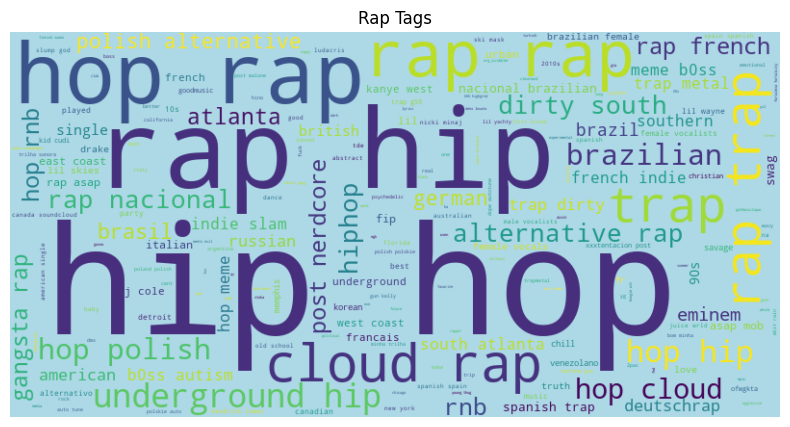

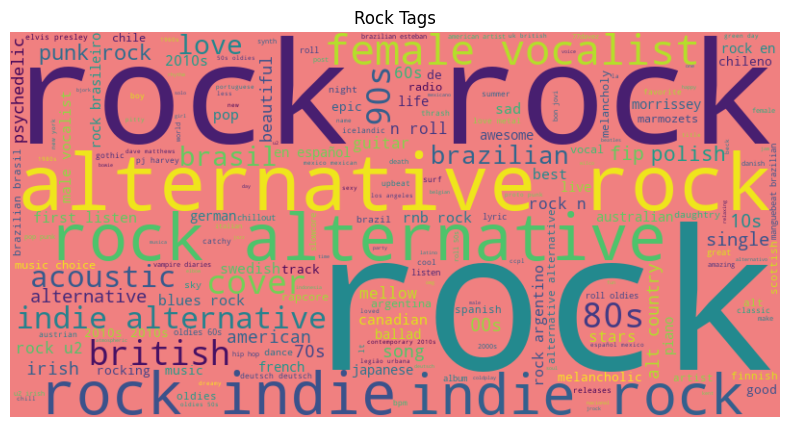

In [151]:
# Creating wordclouds for rap and rock genres
create_wordcloud(rap_tags, 'Rap Tags', color='lightblue')
create_wordcloud(rock_tags, 'Rock Tags', color='lightcoral')


### **Bar Chart**

Present the 10 most appeared tags grouped by the genre of the songs

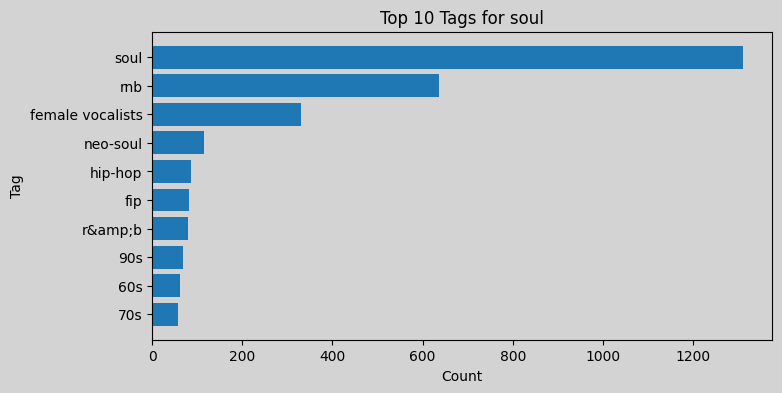

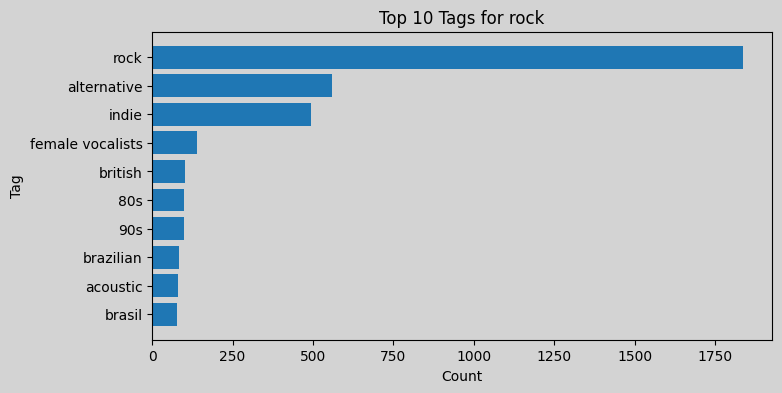

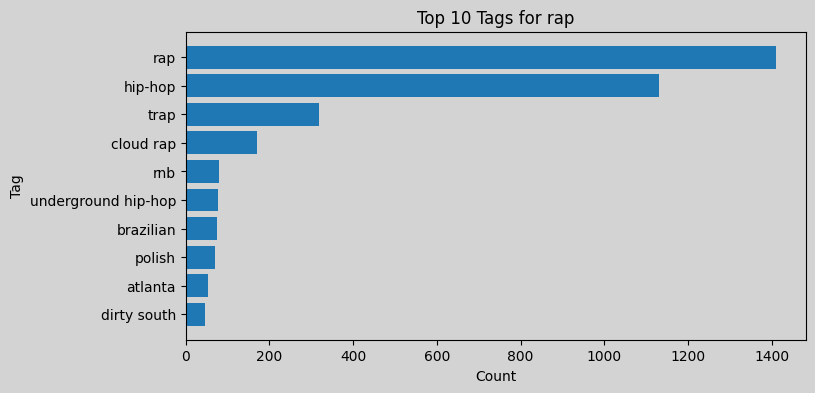

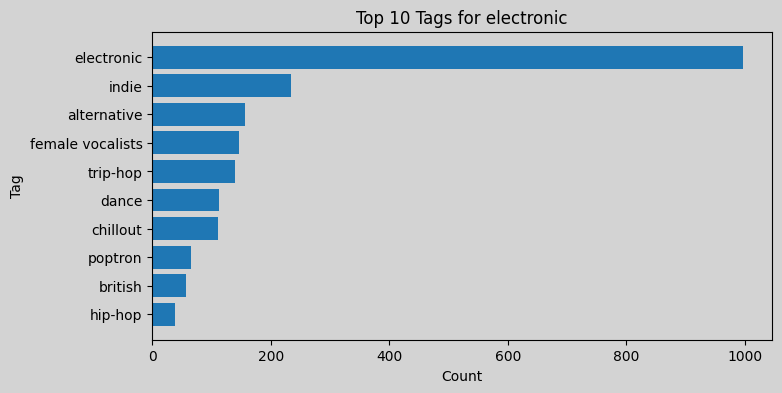

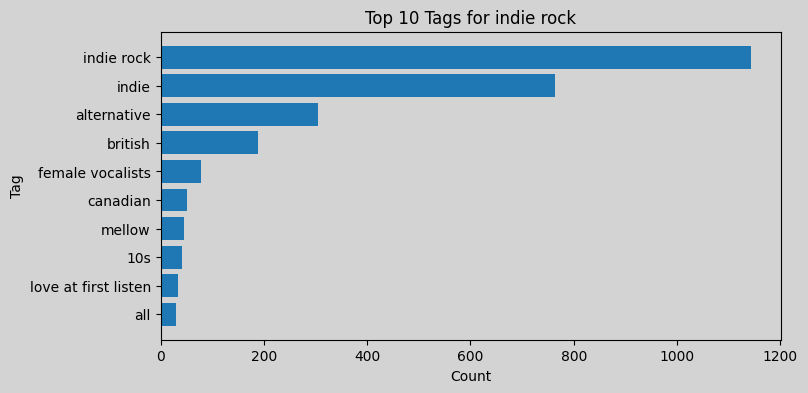

In [152]:
from collections import Counter
import matplotlib.pyplot as plt

data['tags_list'] = data['tags'].fillna('').apply(
    lambda x: [tag.strip() for tag in x.split(',') if tag.strip() != '']
)

for genre in data['genres'].unique():
    subset = data[data['genres'] == genre]

    all_tags = [tag for tags in subset['tags_list'] for tag in tags]

    tag_counts = Counter(all_tags)
    top_tags = tag_counts.most_common(10)

    tags, counts = zip(*top_tags)

    plt.figure(figsize=(8, 4)).patch.set_facecolor('lightgray')
    plt.barh(tags, counts)
    plt.gca().invert_yaxis()
    plt.gca().set_facecolor('lightgray')
    plt.title(f"Top 10 Tags for {genre}")
    plt.xlabel("Count")
    plt.ylabel("Tag")
    plt.show()

### **Dimensionality Reduction**

**Scatter Plot**  
We introduce the following function to help us compare the scatter plots between embedding generated on different bases.

In [153]:
from sklearn.manifold import TSNE

def scatter_plot_comparison(embed1, embed2, title1="PCA Embeddings", title2="Autoencoder Embeddings"):

    # --- t-SNE visualization of the PCA and autoencoder embeddings ---
    tsne = TSNE(n_components=2, learning_rate=200, perplexity=50, max_iter=2000, random_state=42)
    X1 = tsne.fit_transform(embed1)
    X2 = tsne.fit_transform(embed2)

    # --- color the points by genre ---
    categories = data['genres'].astype('category')
    y = categories.cat.codes
    genre_names = categories.cat.categories

    # --- scatter plot of the t-SNE embeddings colored by genre ---
    fig, axes = plt.subplots(1,2, figsize=(12,6))

    scatter1 = axes[0].scatter(X1[:,0], X1[:,1], c=y, cmap='tab10', s=5)
    axes[0].set_title(title1)

    scatter2 = axes[1].scatter(X2[:,0], X2[:,1], c=y, cmap='tab10', s=5)
    axes[1].set_title(title2)

    handles, _ = scatter1.legend_elements()
    axes[1].legend(handles, genre_names, title="Genre", bbox_to_anchor=(1.05, 1), loc='upper left')

    plt.tight_layout()

    plt.show()




**Comparison between PCA and Autoencoder**

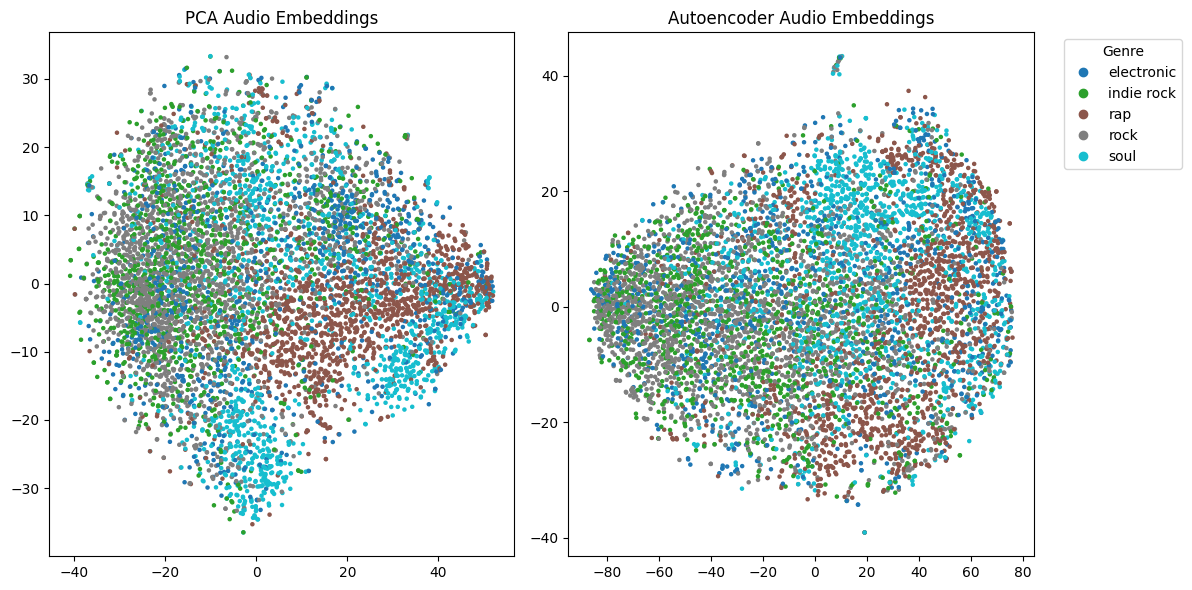

In [154]:
# --- Comparing the PCA and autoencoder embeddings with t-SNE visualization ---
scatter_plot_comparison(pca_audio_embeddings, autoenc_audio_embeddings, title1="PCA Audio Embeddings", title2="Autoencoder Audio Embeddings")

From the visualization of the audio embeddings (both PCA and Autoencoder-based), there is no clear separation between most music genres, as the data points largely overlap. Some genres like Rock and Rap show slightly more distinct patterns, while others such as Pop, Electronic, and Soul appear more mixed.

In the next part, we will introduce classifiers to better capture the underlying structure of the data and improve genre discrimination.

**Comparison between Audio and Text Embeddings**

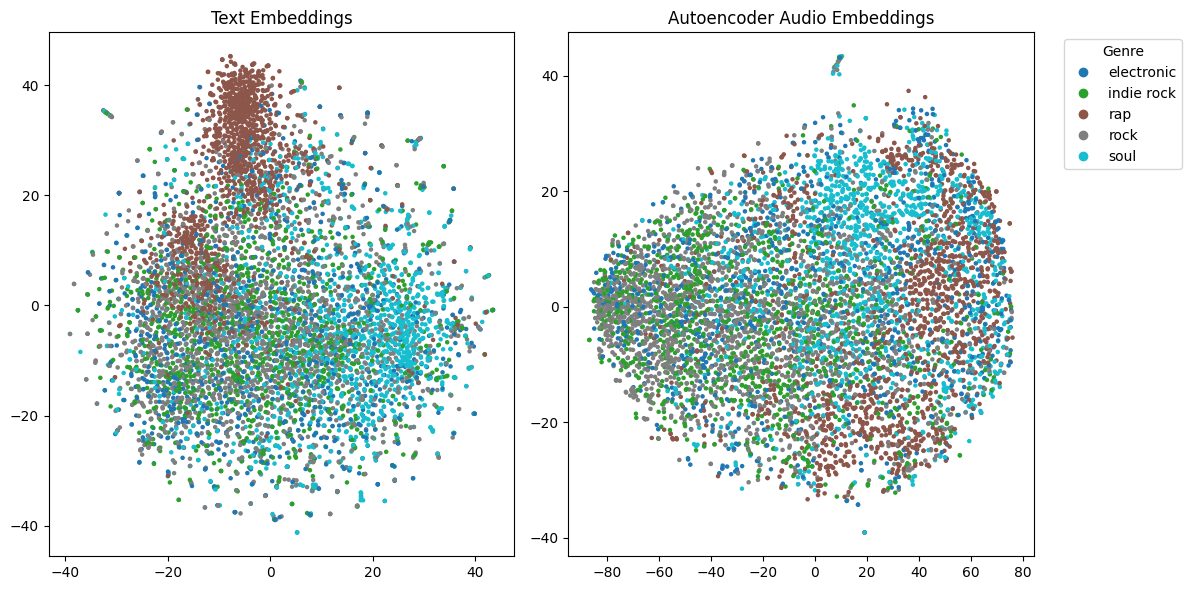

In [155]:
scatter_plot_comparison(embed1=text_embeddings_matrix, embed2=autoenc_audio_embeddings, title1="Text Embeddings", title2="Autoencoder Audio Embeddings")

### **Cosine Similarity**

In [19]:
from sklearn.metrics.pairwise import cosine_similarity

def top_n_similar_songs(song_pos, data, embeddings=autoenc_audio_embeddings, n=5):
    X = embeddings
    similarity_matrix = cosine_similarity(X)
    similarity_df = pd.DataFrame(similarity_matrix, index=data['id'], columns=data['id'])
    song_id = data['id'].iloc[song_pos]      
    similar_songs = similarity_df.loc[song_id].sort_values(ascending=False)[1:n+1]
    similar_songs_ids = similar_songs.index.tolist()
    similar_songs_names = data[data['id'].isin(similar_songs_ids)]['song']
    return similar_songs_names.to_list()



**Cosine similarity: PCA vs Autoencoder**  


In [41]:
# --- Example: top 5 similar songs to the first song in the dataset ---
song_position = 0
top_5_similar_songs = top_n_similar_songs(song_pos=song_position, data=data, embeddings=autoenc_audio_embeddings, n=5)
print("Top 5 similar songs to the first song in the dataset '" + data['song'].iloc[song_position] + "' (Autoencoder):")
print(top_5_similar_songs)

top_5_similar_songs = top_n_similar_songs(song_pos=song_position, data=data, embeddings=pca_audio_embeddings, n=5)
print("Top 5 similar songs to the first song in the dataset '" + data['song'].iloc[song_position] + "' (PCA):")
print(top_5_similar_songs)

Top 5 similar songs to the first song in the dataset 'Rain on Me' (Autoencoder):
['Fake Love', 'From the Bottom of My Broken Heart', 'Breakout', 'Show Me What You Got', 'Quiero']
Top 5 similar songs to the first song in the dataset 'Rain on Me' (PCA):
['One More Night', 'Fight for This Love', 'Dark Horse', 'Moteur Action', 'Lies']



After experimenting on the cosine similarity of the songs and extracting the top-5 similar songs of a variety of songs using the PCA embeddings and the autoencoder embeddings, we notice that similarity results differ between PCA-based and Autoencoder-based embeddings, indicating that each method captures different aspects of the audio data.  
PCA is a linear dimensionality reduction technique that is based on the variance. As a result, it tends to capture more global and general characteristics of the songs and brings close songs with similar high-level structure.  
The Autoencoder, as a non-linear model, learns more complex similarity patterns between the songs and possibly can capture more deep relationships between the MFCC stats.  
Different embedding methods emphasize different properties of the data, leading to different nearest-neighbor relationships between songs.


**Cosine Similarity: Audio Embeddings vs Text Embeddings**